In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import json

import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch import optim
from torch.utils.data import DataLoader, random_split, Subset
from tqdm import tqdm
import matplotlib.pyplot as plt
from pathlib import Path

from autoencoder_mod import FizeauDataset
from configurable_model import ConfigureModel, configAutoenc, random_indices
from astropy.io import fits

from astropy.visualization import ZScaleInterval, ImageNormalize, AsinhStretch

In [2]:
with open("hyperparameter_grid.json", "r") as file:
    hyperparams = json.load(file)

for i in range(len(hyperparams["learning_rate"])):
    lr = hyperparams["learning_rate"][i]
    enc = hyperparams["n_encoder_layers"][i]
    batch_part = hyperparams["batch_part"][i]

"""i, j, k = np.random.randint(0, 2, 3)
lr = hyperparams["learning_rate"][i]
enc = hyperparams["n_encoder_layers"][j]
batch_part = hyperparams["batch_part"][k]
"""
data = {
    "model": {"n_encoder_layers": enc},
    "training": {"learning_rate": lr, "batch_part": batch_part}
}

json_str = json.dumps(data, indent=4)
with open("model_configuration.json", "w") as f:
    f.write(json_str)

In [3]:
n_combinations = 5
random_gridsearch_indices = random_indices(0, 3, 3, n_combinations)
random_gridsearch_indices.shape

(5, 3)

In [4]:
training_frac = 0.8
N = 1001
n_training = int(N*training_frac)
training_epochs = 10

In [5]:
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(torch.get_num_threads(), torch.cuda.is_available())

10 False


In [6]:
data = Path(r"simulated_images_varied_tip_and_tilt_1000")
data = sorted(data.glob("*.fits"))
print(len(data))

dataset = FizeauDataset(data, log=True)

idxs = np.arange(0, N)
np.random.shuffle(idxs)

train_idxs = idxs[:n_training]
validation_idxs = idxs[n_training:n_training + (N-n_training)//2]
test_idxs = idxs[n_training+(N-n_training)//2:]


train_dataset = Subset(dataset, train_idxs)
validation_dataset = Subset(dataset, validation_idxs)
test_dataset = Subset(dataset, test_idxs)

validation_loader = DataLoader(validation_dataset, batch_size=1, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

print(len(train_dataset), len(validation_dataset), len(test_dataset))




1001
800 100 101


In [16]:
loss = nn.L1Loss()
models = []
loss_conf = np.zeros((n_combinations, training_epochs))

with open("hyperparameter_grid.json", "r") as file:
    hyperparams = json.load(file)

for j in range(len(random_gridsearch_indices[:, 0])):
    print(f"training with configuration {j}: {random_gridsearch_indices[j, :]}")
    l, m, n = int(random_gridsearch_indices[j, 0]), int(random_gridsearch_indices[j, 1]), int(random_gridsearch_indices[j, 2])
    
    lr = hyperparams["learning_rate"][l]
    batch_part = hyperparams["batch_part"][m]
    enc = hyperparams["n_encoder_layers"][n]

    configuration = {
    "model": {"n_encoder_layers": enc},
    "training": {"learning_rate": lr, "batch_part": batch_part}
    }

    json_str = json.dumps(configuration, indent=4)
    with open("model_configuration.json", "w") as f:
        f.write(json_str)

    with open("model_configuration.json", "r") as file:
        model_configuration = json.load(file)

    configuration = model_configuration["model"]

    batch_size = int(n_training*batch_part)
    train_loader = DataLoader(train_dataset, batch_size, shuffle=True)

    model = configAutoenc(in_channels=1, in_height=60, configuration=ConfigureModel(**configuration))
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)

    loss_per_epoch = np.zeros(training_epochs)
    validation_loss_per_epoch = []
    epochs_w_no_improvement = 0
    best_model = model
        
    for epoch in range(training_epochs):
        print(f"Epoch [{epoch + 1}/{training_epochs}]")
        model.train()
        batch_losses = []
        
        for batch_index, (data, _) in enumerate(tqdm(iter(train_loader))):
            # Move data and targets to the device (GPU/CPU)
            data = data.to(device)

            # Forward pass: compute the model output
            reconstructed, bottleneck_rep, _, _ = model(data)
            batch_loss = loss(reconstructed, data)
            batch_losses.append(batch_loss.detach().numpy())

            # Backward pass: compute the gradients
            optimizer.zero_grad()
            batch_loss.backward()
    
            # Optimization step: update the model parameters
            optimizer.step()

        #compute mean loss of current epoch
        loss_per_epoch[epoch] = np.mean(batch_losses)

        validation_loss = []
        model.eval()
        with torch.no_grad():
             
            for val_data in validation_loader:
                val_img, _ = val_data
                val_reconstructed, _, _, _ = model(val_img)
                validation_loss.append(loss(val_reconstructed, val_img))

        validation_loss_per_epoch.append(np.mean(validation_loss))

        if epoch >=1:
            if validation_loss_per_epoch[epoch] > validation_loss_per_epoch[epoch-1]:
                epochs_w_no_improvement += 1
            else: epochs_w_no_improvement = 0
            
            if epochs_w_no_improvement > 5:
                break
            else:
                best_model = model
    
    models.append(best_model) 
    loss_conf[j, :] = np.array(loss_per_epoch)



Epoch [1/10]


100%|██████████| 5/5 [00:03<00:00,  1.30it/s]


Epoch [2/10]


100%|██████████| 5/5 [00:02<00:00,  1.87it/s]


Epoch [3/10]


100%|██████████| 5/5 [00:05<00:00,  1.01s/it]


... (90 outputs left out)

Epoch [9/10]


100%|██████████| 5/5 [00:02<00:00,  1.76it/s]


Epoch [10/10]


100%|██████████| 5/5 [00:03<00:00,  1.28it/s]


0.08682787418365479
0.10661891847848892
0.1054292544722557
0.10240107029676437
0.10199379920959473


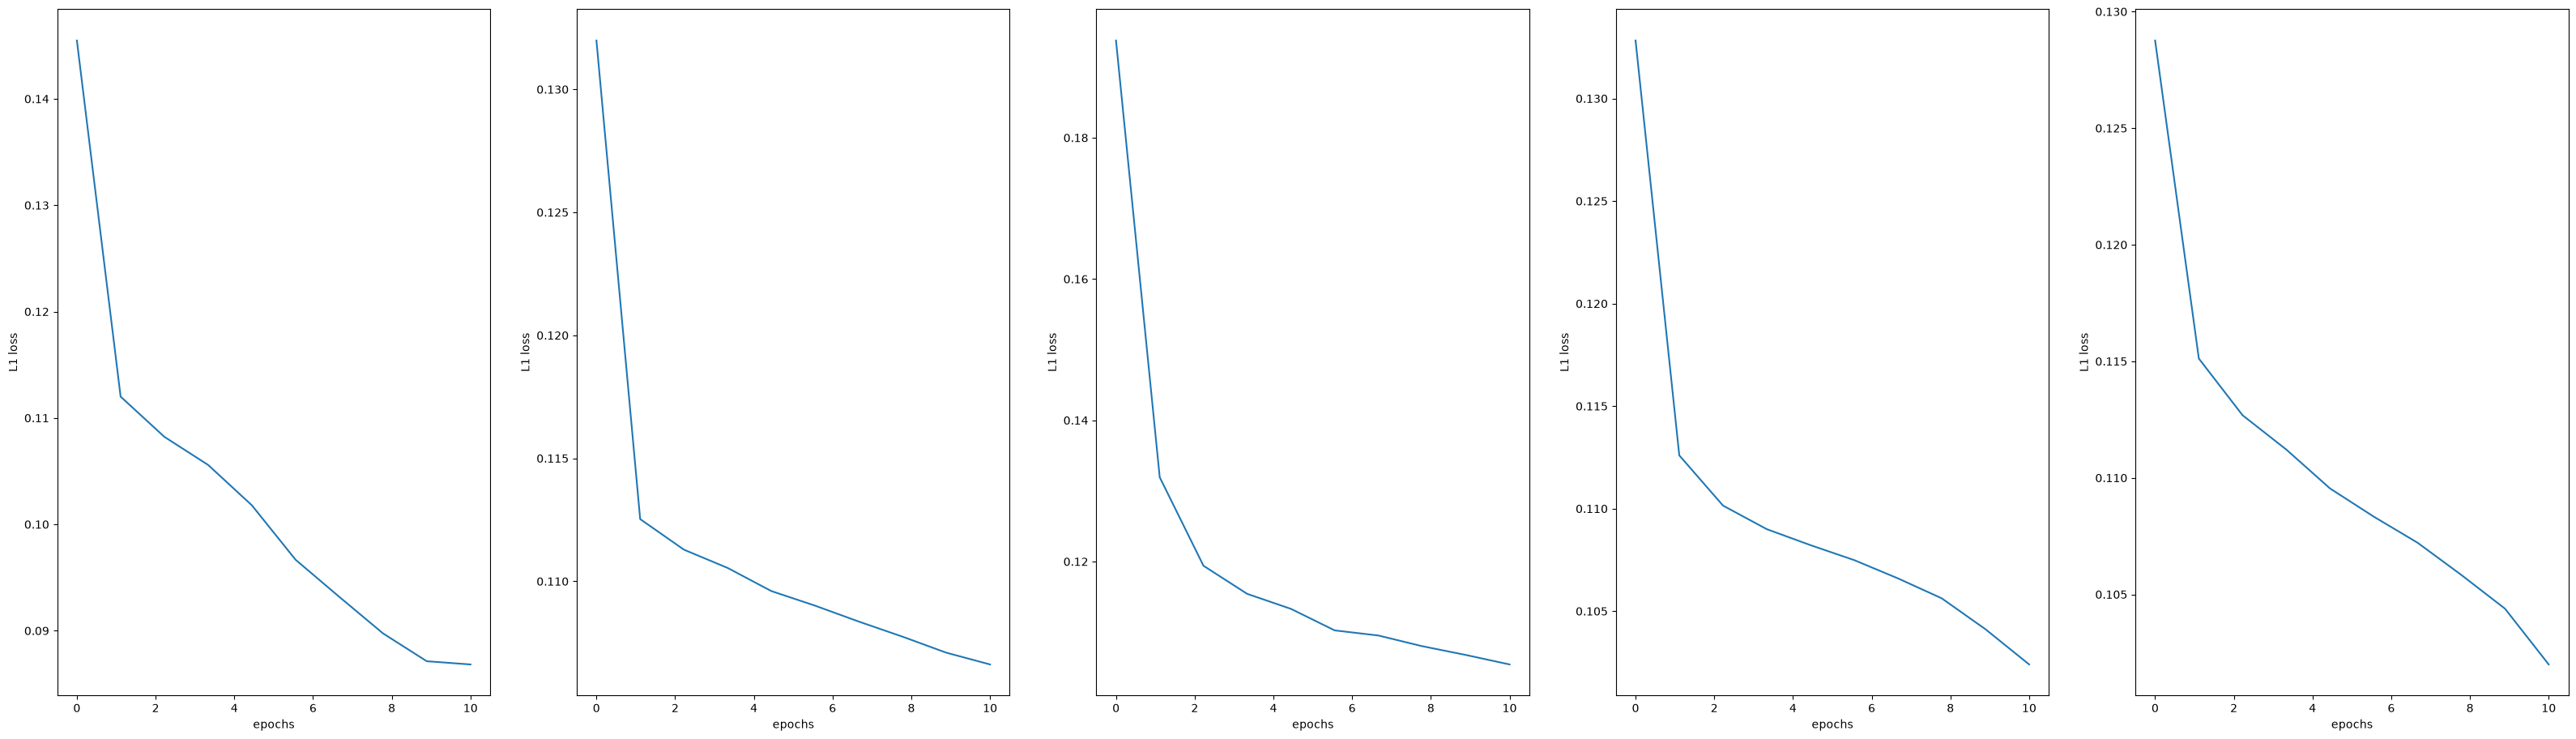

In [17]:
fig, ax = plt.subplots(1, n_combinations)
fig.set_figheight(11)
fig.set_figwidth(40)
epochs = np.linspace(0, training_epochs, num=training_epochs)

for i in range(n_combinations):

    ax[i].plot(epochs, loss_conf[i, :])
    ax[i].set_xlabel("epochs")
    ax[i].set_ylabel("L1 loss")


    print(loss_conf[i, -1])

In [ ]:
model0 = models[0]
model1 = models[1]
model2 = models[2]
model3 = models[3]
model4 = models[4]

In [ ]:
with open("model_configuration.json", "r") as file:
    model_configuration = json.load(file)

configuration = model_configuration["model"]
print(configuration)

model = configAutoenc(in_channels=1, in_height=60, configuration=ConfigureModel(**configuration))
img, _ = train_loader.dataset[1]
img = torch.unsqueeze(img, 0)
slay, bottleneck_rep, latent_reps, bn_dim = model(img)

{'n_encoder_layers': 5}
